In [ ]:
# BLOCK 1 — Install/import packages, configure reproducibility and output folders
!pip -q install tensorflow-datasets scikit-learn pandas matplotlib seaborn

import os, time, json, math, random, shutil, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 5                 # Increase to 10–20 for stronger results if GPU/time permits
FROZEN_EPOCHS = max(1, EPOCHS - 2)
FINE_TUNE_LR = 1e-5
HEAD_LR = 1e-3
DROPOUT = 0.25
RUN_EXTENDED = True        # True: run main ablations + SE/ECA/CBAM + order/kernel/multi-stage tests
RUN_P2 = True              # P2 is compute-heavy; turn off if Colab memory/time is limited
MAX_TRAIN = None           # e.g. 1500 for a quick smoke test; None uses full split
MAX_VAL = None
MAX_TEST = None

OUT = Path("/content/attention_lab_results")
FIG = OUT / "figures"
CSV = OUT / "tables"
CKPT = OUT / "checkpoints"
for p in (OUT, FIG, CSV, CKPT): p.mkdir(parents=True, exist_ok=True)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Output folder:", OUT)


TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output folder: /content/attention_lab_results


In [ ]:
!pip install --upgrade pip
!pip install --upgrade importlib-resources
!pip install --upgrade tensorflow-datasets

import importlib_resources
print("importlib_resources installed successfully!")

importlib_resources installed successfully!


In [ ]:
# BLOCK 2 — FIXED: Load dataset, create split, and prepare pipelines

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

# Load TensorFlow Flowers
(ds_all, ds_info) = tfds.load(
    "tf_flowers",
    split="train",
    as_supervised=True,
    with_info=True
)

class_names = ds_info.features["label"].names
print("Classes:", class_names)
print("Dataset size:", ds_info.splits["train"].num_examples)

# IMPORTANT: Keep images as a Python list because image dimensions vary.
images = []
labels = []

for image, label in tfds.as_numpy(ds_all):
    images.append(image)
    labels.append(int(label))

# Convert labels only to a NumPy array.
labels = np.asarray(labels, dtype=np.int32)

print("Number of images:", len(images))
print("Number of labels:", len(labels))

assert len(images) == len(labels), (
    f"Mismatch: {len(images)} images vs {len(labels)} labels"
)

# Create reproducible 70:15:15 stratified split.
indices = np.arange(len(labels))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=labels[temp_idx]
)

print(f"Training images:   {len(train_idx)}")
print(f"Validation images: {len(val_idx)}")
print(f"Testing images:    {len(test_idx)}")

# Resize and prepare images.
def decode_resize(image, label):
    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        antialias=True
    )
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

# Create datasets.
def make_dataset(index_list, training=False):

    selected_images = [images[i] for i in index_list]
    selected_labels = labels[index_list]

    def generator():
        for image, label in zip(selected_images, selected_labels):
            yield image, label

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(
                shape=(None, None, 3),
                dtype=tf.uint8
            ),
            tf.TensorSpec(
                shape=(),
                dtype=tf.int32
            )
        )
    )

    ds = ds.map(
        decode_resize,
        num_parallel_calls=AUTOTUNE
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(index_list), 2048),
            seed=SEED,
            reshuffle_each_iteration=True
        )

        def augment(image, label):
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_brightness(
                image,
                max_delta=0.08
            )
            image = tf.image.random_contrast(
                image,
                lower=0.9,
                upper=1.1
            )
            return image, label

        ds = ds.map(
            augment,
            num_parallel_calls=AUTOTUNE
        )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_idx, training=True)
val_ds = make_dataset(val_idx, training=False)
test_ds = make_dataset(test_idx, training=False)

# Verify one batch.
for batch_images, batch_labels in train_ds.take(1):
    print("Batch image shape:", batch_images.shape)
    print("Batch label shape:", batch_labels.shape)

print("BLOCK 2 completed successfully!")

Classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Dataset size: 3670
Number of images: 3670
Number of labels: 3670
Training images:   2569
Validation images: 550
Testing images:    551
Batch image shape: (16, 224, 224, 3)
Batch label shape: (16,)
BLOCK 2 completed successfully!


In [ ]:

# BLOCK 3 — FIXED Attention layers and ResNet50 model builder

from tensorflow.keras import layers, Model

# --------------------------------------------------
# Channel Attention
# --------------------------------------------------
@tf.keras.utils.register_keras_serializable()
class ChannelAttention(layers.Layer):
    def __init__(self, reduction=16, **kwargs):
        super().__init__(**kwargs)
        self.reduction = reduction

    def build(self, input_shape):
        channels = int(input_shape[-1])

        self.gap = layers.GlobalAveragePooling2D(
            keepdims=True,
            data_format="channels_last"
        )
        self.fc1 = layers.Conv2D(
            max(channels // self.reduction, 1),
            kernel_size=1,
            activation="relu"
        )
        self.fc2 = layers.Conv2D(
            channels,
            kernel_size=1,
            activation="sigmoid"
        )
        super().build(input_shape)

    def call(self, x):
        weights = self.fc2(self.fc1(self.gap(x)))
        return x * weights

    def get_config(self):
        return {
            **super().get_config(),
            "reduction": self.reduction
        }


# --------------------------------------------------
# Spatial Attention
# --------------------------------------------------
@tf.keras.utils.register_keras_serializable()
class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size
        self.conv = layers.Conv2D(
            filters=1,
            kernel_size=kernel_size,
            padding="same",
            activation="sigmoid",
            use_bias=False
        )

    def call(self, x):
        avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        maximum = tf.reduce_max(x, axis=-1, keepdims=True)

        attention_map = self.conv(
            tf.concat([avg, maximum], axis=-1)
        )

        return x * attention_map

    def get_config(self):
        return {
            **super().get_config(),
            "kernel_size": self.kernel_size
        }


# --------------------------------------------------
# Self Attention
# --------------------------------------------------
@tf.keras.utils.register_keras_serializable()
class SelfAttention2D(layers.Layer):
    def __init__(self, key_ratio=8, **kwargs):
        super().__init__(**kwargs)
        self.key_ratio = key_ratio

    def build(self, input_shape):
        channels = int(input_shape[-1])
        dim = max(channels // self.key_ratio, 8)

        self.q = layers.Conv2D(dim, 1, use_bias=False)
        self.k = layers.Conv2D(dim, 1, use_bias=False)
        self.v = layers.Conv2D(channels, 1, use_bias=False)

        self.gamma = self.add_weight(
            name="gamma",
            shape=(),
            initializer="zeros",
            trainable=True
        )
        super().build(input_shape)

    def call(self, x):
        shape = tf.shape(x)
        batch, height, width = shape[0], shape[1], shape[2]

        q = tf.reshape(self.q(x), (batch, height * width, -1))
        k = tf.reshape(self.k(x), (batch, height * width, -1))
        v = tf.reshape(self.v(x), (batch, height * width, -1))

        logits = tf.matmul(q, k, transpose_b=True)
        logits /= tf.sqrt(
            tf.cast(tf.shape(k)[-1], tf.float32)
        )

        weights = tf.nn.softmax(logits, axis=-1)
        output = tf.matmul(weights, v)

        output = tf.reshape(
            output,
            (batch, height, width, tf.shape(output)[-1])
        )

        return x + self.gamma * output

    def get_config(self):
        return {
            **super().get_config(),
            "key_ratio": self.key_ratio
        }


# --------------------------------------------------
# ECA Attention
# --------------------------------------------------
@tf.keras.utils.register_keras_serializable()
class ECAAttention(layers.Layer):
    def __init__(self, kernel_size=3, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = kernel_size
        self.conv = layers.Conv1D(
            1, kernel_size, padding="same", use_bias=False
        )

    def call(self, x):
        weights = tf.reduce_mean(x, axis=[1, 2])
        weights = tf.expand_dims(weights, axis=-1)
        weights = tf.sigmoid(self.conv(weights))
        weights = tf.transpose(weights, [0, 2, 1])
        weights = weights[:, None, None, :]

        return x * weights

    def get_config(self):
        return {
            **super().get_config(),
            "kernel_size": self.kernel_size
        }


# --------------------------------------------------
# Other attention variants
# --------------------------------------------------
@tf.keras.utils.register_keras_serializable()
class SEAttention(ChannelAttention):
    pass


@tf.keras.utils.register_keras_serializable()
class CBAMAttention(layers.Layer):
    def __init__(self, reduction=16, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction = reduction
        self.kernel_size = kernel_size
        self.ca = ChannelAttention(reduction)
        self.sa = SpatialAttention(kernel_size)

    def call(self, x):
        return self.sa(self.ca(x))

    def get_config(self):
        return {
            **super().get_config(),
            "reduction": self.reduction,
            "kernel_size": self.kernel_size
        }


@tf.keras.utils.register_keras_serializable()
class CoordinateAttentionApprox(layers.Layer):
    def __init__(self, reduction=16, **kwargs):
        super().__init__(**kwargs)
        self.reduction = reduction

    def build(self, input_shape):
        channels = int(input_shape[-1])
        middle = max(channels // self.reduction, 8)

        self.reduce = layers.Conv2D(
            middle, 1, activation="relu"
        )
        self.hproj = layers.Conv2D(
            channels, 1, activation="sigmoid"
        )
        self.wproj = layers.Conv2D(
            channels, 1, activation="sigmoid"
        )
        super().build(input_shape)

    def call(self, x):
        h = tf.reduce_mean(x, axis=2, keepdims=True)
        w = tf.reduce_mean(x, axis=1, keepdims=True)

        return (
            x
            * self.hproj(self.reduce(h))
            * self.wproj(self.reduce(w))
        )

    def get_config(self):
        return {
            **super().get_config(),
            "reduction": self.reduction
        }


# --------------------------------------------------
# ResNet50 stage definitions
# --------------------------------------------------
STAGE_LAYER = {
    "P1": "conv2_block3_out",
    "P2": "conv3_block4_out",
    "P3": "conv4_block6_out",
    "P4": "conv5_block3_out"
}

STAGE_SHAPES = {
    "P1": "56x56x256",
    "P2": "28x28x512",
    "P3": "14x14x1024",
    "P4": "7x7x2048"
}


# --------------------------------------------------
# FIXED Model builder
# --------------------------------------------------
def build_model(
    attention="none",
    position="P3",
    order="channel_spatial",
    kernel_size=7,
    multi_positions=None
):
    inp = layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image"
    )

    # Preprocess the RGB image.
    preprocessed = tf.keras.applications.resnet50.preprocess_input(inp)

    # Build ResNet50 once.
    backbone = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=preprocessed
    )
    backbone.trainable = False

    positions = multi_positions or [position]

    if len(positions) != 1:
        raise NotImplementedError(
            "This builder currently supports one attention position "
            "per model. Use multi_positions=None for P1, P2, P3 or P4."
        )

    if positions[0] not in STAGE_LAYER:
        raise ValueError(f"Unknown position: {positions[0]}")

    # Extract the selected 4D feature map.
    feature_extractor = Model(
        inputs=backbone.input,
        outputs=backbone.get_layer(
            STAGE_LAYER[positions[0]]
        ).output,
        name=f"features_{positions[0]}"
    )

    target = feature_extractor(preprocessed)

    # The selected ResNet feature must be 4D.
    if len(target.shape) != 4:
        raise ValueError(
            f"Expected a 4D feature map, got shape {target.shape}"
        )

    print("Selected feature shape:", target.shape)

    z = target

    if attention == "channel":
        z = ChannelAttention(name="channel_attention")(z)

    elif attention == "spatial":
        z = SpatialAttention(
            kernel_size, name="spatial_attention"
        )(z)

    elif attention == "channel_spatial":
        if order == "channel_spatial":
            z = ChannelAttention(name="channel_attention")(z)
            z = SpatialAttention(
                kernel_size, name="spatial_attention"
            )(z)
        else:
            z = SpatialAttention(
                kernel_size, name="spatial_attention"
            )(z)
            z = ChannelAttention(name="channel_attention")(z)

    elif attention == "self":
        z = SelfAttention2D(name="self_attention")(z)

    elif attention == "se":
        z = SEAttention(name="se_attention")(z)

    elif attention == "eca":
        z = ECAAttention(name="eca_attention")(z)

    elif attention == "cbam":
        z = CBAMAttention(
            kernel_size=kernel_size,
            name="cbam_attention"
        )(z)

    elif attention == "coordinate":
        z = CoordinateAttentionApprox(
            name="coordinate_attention"
        )(z)

    elif attention == "combined":
        z = ChannelAttention(name="channel_attention")(z)
        z = SpatialAttention(
            kernel_size, name="spatial_attention"
        )(z)
        z = SelfAttention2D(name="self_attention")(z)

    elif attention != "none":
        raise ValueError(f"Unknown attention type: {attention}")

    # This layer now receives a 4D feature map.
    z = layers.GlobalAveragePooling2D(name="gap")(z)
    z = layers.Dropout(DROPOUT, name="dropout")(z)

    out = layers.Dense(
        5, activation="softmax", name="flower_predictions"
    )(z)

    model = Model(
        inputs=inp,
        outputs=out,
        name=f"ResNet50_{attention}_{positions[0]}"
    )

    model.backbone = backbone
    model.feature_model = feature_extractor
    model.attention_type = attention
    model.position = positions[0]

    return model


def compile_model(model, lr=HEAD_LR):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def count_parameters(model):
    total = model.count_params()
    trainable = int(
        np.sum([
            tf.keras.backend.count_params(w)
            for w in model.trainable_weights
        ])
    )
    return total, trainable


print("Corrected attention layers and model builder are ready.")


Corrected attention layers and model builder are ready.


In [ ]:
# BLOCK 4 — Training runner, fine-tuning, evaluation metrics, histories and checkpoints
results = []
histories = {}
models = {}

def collect_predictions(model, dataset):
    y_true, y_prob = [], []
    for xb, yb in dataset:
        probs = model.predict(xb, verbose=0)
        y_true.extend(yb.numpy().tolist()); y_prob.extend(probs.tolist())
    return np.asarray(y_true), np.asarray(y_prob)

def evaluate_model(model, name, position, attention):
    # Warm-up + repeated batches for more stable per-image inference timing.
    xb, yb = next(iter(test_ds))
    _ = model(xb[:1], training=False)
    t0 = time.perf_counter()
    n = 0
    for xb, _ in test_ds:
        _ = model(xb, training=False); n += int(xb.shape[0])
    infer_ms = (time.perf_counter()-t0) * 1000 / max(n,1)
    y_true, probs = collect_predictions(model, test_ds)
    y_pred = probs.argmax(axis=1)
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(5), average="macro", zero_division=0)
    total, trainable = count_parameters(model)
    row = {"Model":name, "Attention":attention, "Position":position,
           "Accuracy":acc, "Precision":precision, "Recall":recall, "Macro F1":f1,
           "Trainable Parameters":trainable, "Total Parameters":total,
           "Inference ms/image":infer_ms}
    results.append(row)
    np.savez_compressed(CSV/f"{name.replace(' ','_')}_predictions.npz", y_true=y_true, y_pred=y_pred, probs=probs)
    return row, y_true, y_pred, probs

def run_experiment(name, attention="none", position="P3", order="channel_spatial",
                   kernel_size=7, multi_positions=None, epochs=EPOCHS):
    tf.keras.backend.clear_session()
    model = build_model(attention, position, order, kernel_size, multi_positions)
    compile_model(model, HEAD_LR)
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
        tf.keras.callbacks.ModelCheckpoint(str(CKPT/f"{name.replace(' ','_')}.weights.h5"),
                                           monitor="val_loss", save_best_only=True, save_weights_only=True)
    ]
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=1)
    # Fine-tune final ResNet stage; lower LR as recommended in the lab brief.
    # Feature-level model only uses the selected stage output; unfreezing the backbone allows selected features to adapt.
    model.backbone.trainable = True
    for layer in model.backbone.layers:
        layer.trainable = layer.name.startswith("conv5_") or layer.name.startswith("conv4_")
    compile_model(model, FINE_TUNE_LR)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=2, callbacks=callbacks, verbose=1)
    history = {}
    for key in set(h1.history) | set(h2.history):
        history[key] = list(h1.history.get(key, [])) + list(h2.history.get(key, []))
    histories[name] = history
    model.save_weights(CKPT/f"{name.replace(' ','_')}_final.weights.h5")
    models[name] = model
    row, yt, yp, probs = evaluate_model(model, name, position if not multi_positions else "+".join(multi_positions), attention)
    print("\n", name, "\n", pd.Series(row).to_string())
    return model, row

def plot_history(name, history):
    epochs = range(1, len(history.get("accuracy",[]))+1)
    fig, ax = plt.subplots(1,2,figsize=(12,4))
    ax[0].plot(epochs, history.get("accuracy",[]), marker="o", label="Train")
    ax[0].plot(epochs, history.get("val_accuracy",[]), marker="o", label="Validation")
    ax[0].set_title(f"{name}: accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend(); ax[0].grid(True, alpha=.3)
    ax[1].plot(epochs, history.get("loss",[]), marker="o", label="Train")
    ax[1].plot(epochs, history.get("val_loss",[]), marker="o", label="Validation")
    ax[1].set_title(f"{name}: loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Cross-entropy loss"); ax[1].legend(); ax[1].grid(True, alpha=.3)
    plt.tight_layout(); safe = name.replace(" ","_").replace("+","plus")
    plt.savefig(FIG/f"history_{safe}.png", dpi=200, bbox_inches="tight"); plt.show()

print("Runner ready.")


Runner ready.


Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.5524 - loss: 1.1442 - val_accuracy: 0.7873 - val_loss: 0.6885 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 68ms/step - accuracy: 0.7583 - loss: 0.6815 - val_accuracy: 0.8218 - val_loss: 0.5493 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 81ms/step - accuracy: 0.7933 - loss: 0.5688 - val_accuracy: 0.8491 - val_loss: 0.4644 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 67ms/step - accuracy: 0.8287 - loss: 0.4929 - val_accuracy: 0.8400 - val_loss: 0.4402 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 66ms/step - accuracy: 0.8287 - loss: 0.4723 - val_accuracy: 0.8745 - val_loss: 0.4100 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 70s 207ms/step - accuracy: 0.7995 - loss: 0.5550 - val_accuracy: 0.8873 - val_loss: 0.3311 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━━

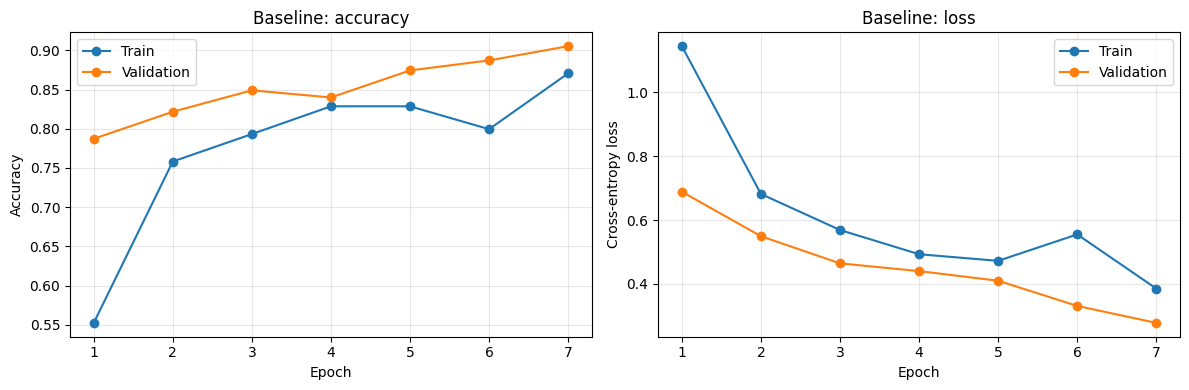

Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 40s 140ms/step - accuracy: 0.6481 - loss: 0.9139 - val_accuracy: 0.7691 - val_loss: 0.6478 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - accuracy: 0.8174 - loss: 0.5004 - val_accuracy: 0.8436 - val_loss: 0.4311 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 74ms/step - accuracy: 0.8521 - loss: 0.4041 - val_accuracy: 0.8818 - val_loss: 0.3643 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 82ms/step - accuracy: 0.8723 - loss: 0.3475 - val_accuracy: 0.8800 - val_loss: 0.3255 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 77ms/step - accuracy: 0.8848 - loss: 0.3284 - val_accuracy: 0.8764 - val_loss: 0.3193 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 66s 214ms/step - accuracy: 0.8583 - loss: 0.4105 - val_accuracy: 0.9073 - val_loss: 0.2760 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━━

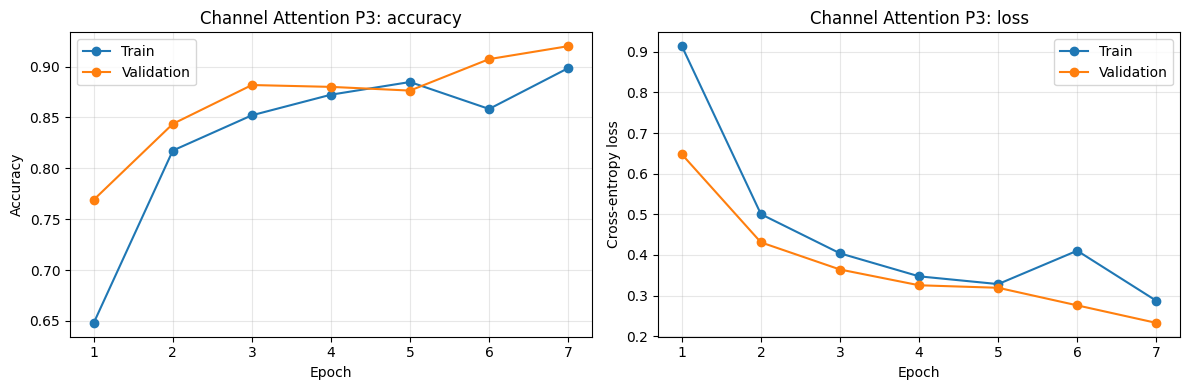

Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 40s 139ms/step - accuracy: 0.5827 - loss: 1.0502 - val_accuracy: 0.8182 - val_loss: 0.5967 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 70ms/step - accuracy: 0.7750 - loss: 0.6206 - val_accuracy: 0.8418 - val_loss: 0.4776 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - accuracy: 0.8163 - loss: 0.5190 - val_accuracy: 0.8691 - val_loss: 0.4204 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 74ms/step - accuracy: 0.8276 - loss: 0.4847 - val_accuracy: 0.8727 - val_loss: 0.4023 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - accuracy: 0.8357 - loss: 0.4518 - val_accuracy: 0.8800 - val_loss: 0.3864 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 65s 207ms/step - accuracy: 0.8050 - loss: 0.5459 - val_accuracy: 0.8855 - val_loss: 0.3269 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━━

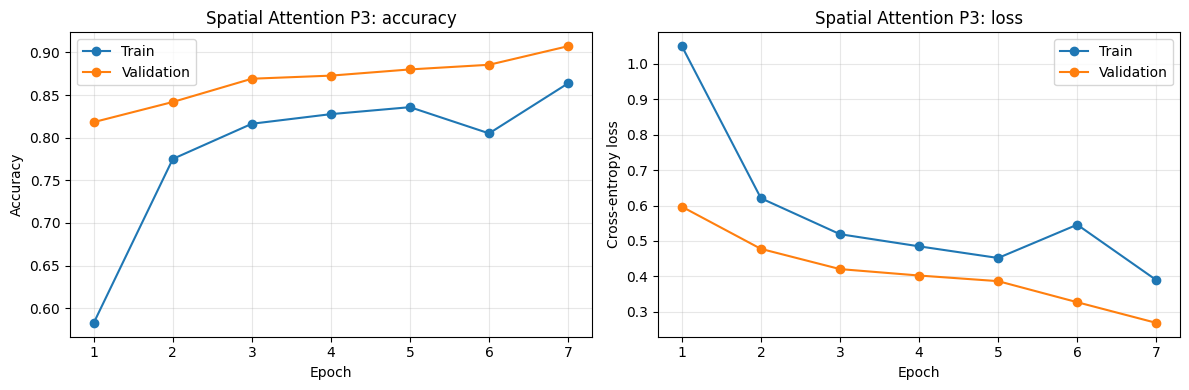

Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 41s 141ms/step - accuracy: 0.6582 - loss: 0.8930 - val_accuracy: 0.8309 - val_loss: 0.5274 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step - accuracy: 0.8132 - loss: 0.4939 - val_accuracy: 0.8291 - val_loss: 0.5025 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 74ms/step - accuracy: 0.8455 - loss: 0.4088 - val_accuracy: 0.8491 - val_loss: 0.4343 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 69ms/step - accuracy: 0.8661 - loss: 0.3643 - val_accuracy: 0.8891 - val_loss: 0.3401 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 82ms/step - accuracy: 0.8801 - loss: 0.3399 - val_accuracy: 0.8491 - val_loss: 0.4123 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 67s 219ms/step - accuracy: 0.8318 - loss: 0.4621 - val_accuracy: 0.9055 - val_loss: 0.2872 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━━

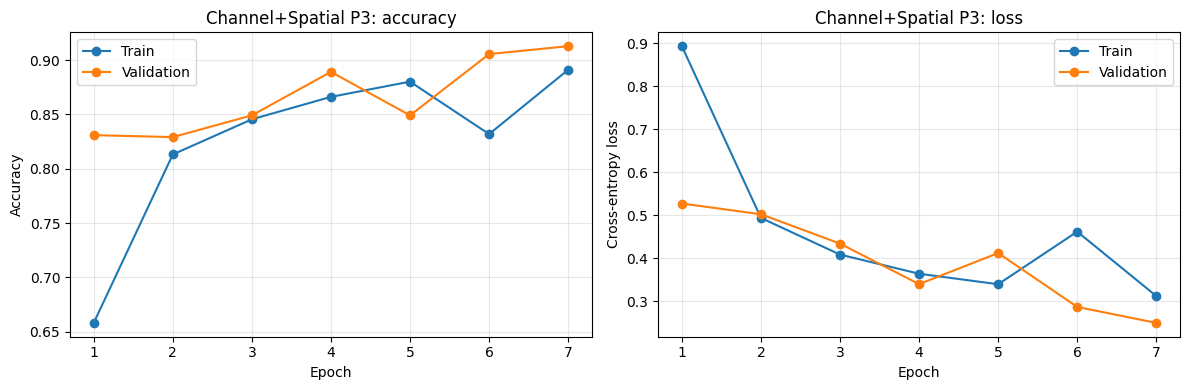

Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 47s 163ms/step - accuracy: 0.5722 - loss: 1.0669 - val_accuracy: 0.7818 - val_loss: 0.5996 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 80ms/step - accuracy: 0.8186 - loss: 0.4973 - val_accuracy: 0.8455 - val_loss: 0.4219 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.8606 - loss: 0.3803 - val_accuracy: 0.8727 - val_loss: 0.3615 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 84ms/step - accuracy: 0.8867 - loss: 0.3171 - val_accuracy: 0.8836 - val_loss: 0.3383 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 79ms/step - accuracy: 0.9109 - loss: 0.2673 - val_accuracy: 0.9000 - val_loss: 0.3113 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 68s 225ms/step - accuracy: 0.8669 - loss: 0.3626 - val_accuracy: 0.8945 - val_loss: 0.3032 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━━

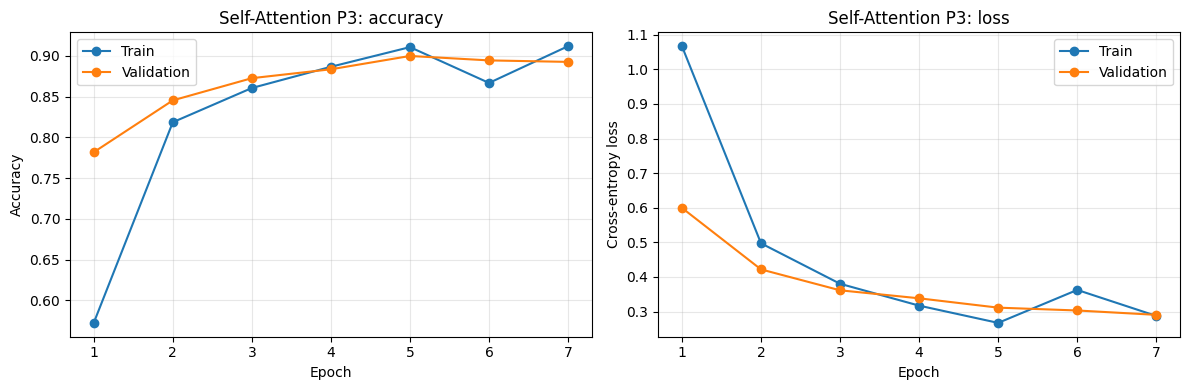

Selected feature shape: (None, 28, 28, 512)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 36s 120ms/step - accuracy: 0.4305 - loss: 1.3029 - val_accuracy: 0.7055 - val_loss: 0.8032 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 58ms/step - accuracy: 0.7038 - loss: 0.7917 - val_accuracy: 0.7418 - val_loss: 0.6944 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 63ms/step - accuracy: 0.7260 - loss: 0.7199 - val_accuracy: 0.7582 - val_loss: 0.6384 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - accuracy: 0.7443 - loss: 0.6694 - val_accuracy: 0.7836 - val_loss: 0.5699 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 49ms/step - accuracy: 0.7458 - loss: 0.6632 - val_accuracy: 0.7582 - val_loss: 0.6035 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 107ms/step - accuracy: 0.7707 - loss: 0.6204 - val_accuracy: 0.7891 - val_loss: 0.5626 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━━━

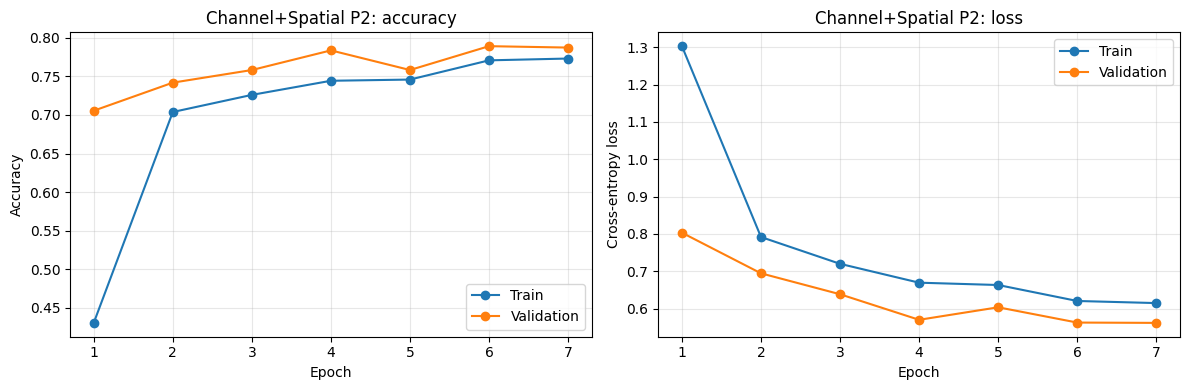

Selected feature shape: (None, 7, 7, 2048)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 180ms/step - accuracy: 0.7886 - loss: 0.5660 - val_accuracy: 0.8818 - val_loss: 0.3643 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 83ms/step - accuracy: 0.8949 - loss: 0.2953 - val_accuracy: 0.8891 - val_loss: 0.3014 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 80ms/step - accuracy: 0.9284 - loss: 0.2097 - val_accuracy: 0.8709 - val_loss: 0.3461 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 40s 75ms/step - accuracy: 0.9467 - loss: 0.1519 - val_accuracy: 0.8964 - val_loss: 0.3427 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step - accuracy: 0.9770 - loss: 0.0737 - val_accuracy: 0.9091 - val_loss: 0.3126 - learning_rate: 3.0000e-04
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 102s 343ms/step - accuracy: 0.8661 - loss: 0.3864 - val_accuracy: 0.9055 - val_loss: 0.2782 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━

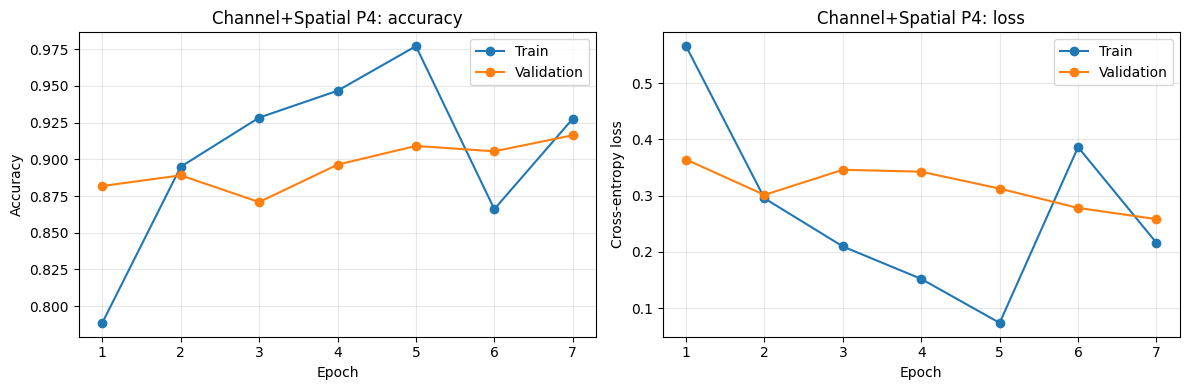

In [ ]:
# BLOCK 5 — Run mandatory main experiments (baseline, attention type, attention position, self-attention)
# Mandatory set from the report: baseline; channel P3; spatial P3; channel+spatial P2/P3/P4; self-attention P3.
# In this code P3 = after conv4_x (14x14x1024), matching the report's principal position.
EXPERIMENTS = [
    ("Baseline", "none", "P3", "channel_spatial", 7),
    ("Channel Attention P3", "channel", "P3", "channel_spatial", 7),
    ("Spatial Attention P3", "spatial", "P3", "channel_spatial", 7),
    ("Channel+Spatial P3", "channel_spatial", "P3", "channel_spatial", 7),
    ("Self-Attention P3", "self", "P3", "channel_spatial", 7),
]
if RUN_P2:
    EXPERIMENTS += [("Channel+Spatial P2", "channel_spatial", "P2", "channel_spatial", 7)]
EXPERIMENTS += [("Channel+Spatial P4", "channel_spatial", "P4", "channel_spatial", 7)]

for name, attn, pos, order, k in EXPERIMENTS:
    if name not in models:
        model, row = run_experiment(name, attn, pos, order, k)
        plot_history(name, histories[name])


Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 46s 163ms/step - accuracy: 0.7330 - loss: 0.6985 - val_accuracy: 0.8745 - val_loss: 0.3833 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step - accuracy: 0.8544 - loss: 0.3846 - val_accuracy: 0.8600 - val_loss: 0.4082 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 27s 129ms/step - accuracy: 0.8883 - loss: 0.3095 - val_accuracy: 0.8927 - val_loss: 0.3337 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 37s 93ms/step - accuracy: 0.9019 - loss: 0.2631 - val_accuracy: 0.9036 - val_loss: 0.3266 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 0.9257 - loss: 0.2254 - val_accuracy: 0.9036 - val_loss: 0.3232 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 76s 267ms/step - accuracy: 0.8980 - loss: 0.2877 - val_accuracy: 0.8927 - val_loss: 0.3106 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━━━

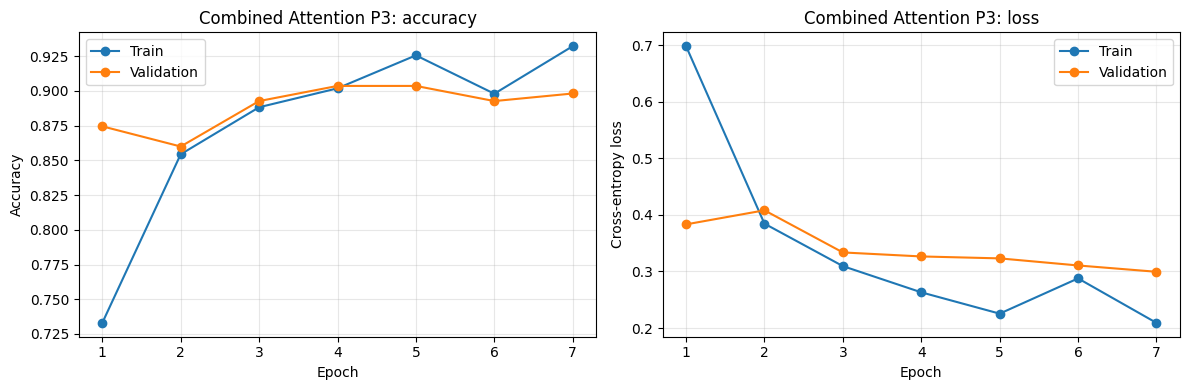

Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 45s 168ms/step - accuracy: 0.6983 - loss: 0.8428 - val_accuracy: 0.8527 - val_loss: 0.4875 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 37s 170ms/step - accuracy: 0.8151 - loss: 0.4971 - val_accuracy: 0.8400 - val_loss: 0.4612 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 25s 108ms/step - accuracy: 0.8474 - loss: 0.4089 - val_accuracy: 0.8709 - val_loss: 0.3713 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 100ms/step - accuracy: 0.8704 - loss: 0.3505 - val_accuracy: 0.8782 - val_loss: 0.3352 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 17s 65ms/step - accuracy: 0.8856 - loss: 0.3173 - val_accuracy: 0.8709 - val_loss: 0.3535 - learning_rate: 0.0010
Epoch 1/2
161/161 ━━━━━━━━━━━━━━━━━━━━ 73s 258ms/step - accuracy: 0.8638 - loss: 0.3844 - val_accuracy: 0.9018 - val_loss: 0.2822 - learning_rate: 1.0000e-05
Epoch 2/2
161/161 ━━━━━━━━━━

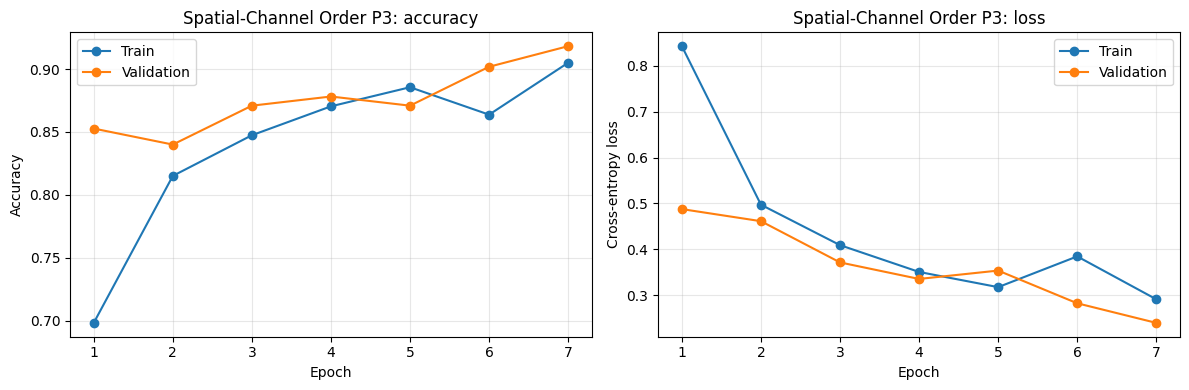

Selected feature shape: (None, 14, 14, 1024)
Epoch 1/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 141s 155ms/step - accuracy: 0.6726 - loss: 0.8998 - val_accuracy: 0.8400 - val_loss: 0.4968 - learning_rate: 0.0010
Epoch 2/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 25s 113ms/step - accuracy: 0.8268 - loss: 0.4837 - val_accuracy: 0.8764 - val_loss: 0.3742 - learning_rate: 0.0010
Epoch 3/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step - accuracy: 0.8568 - loss: 0.3981 - val_accuracy: 0.8545 - val_loss: 0.3948 - learning_rate: 0.0010
Epoch 4/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 19s 70ms/step - accuracy: 0.8708 - loss: 0.3599 - val_accuracy: 0.8182 - val_loss: 0.4843 - learning_rate: 0.0010
Epoch 5/5
161/161 ━━━━━━━━━━━━━━━━━━━━ 27s 128ms/step - accuracy: 0.8949 - loss: 0.2877 - val_accuracy: 0.8945 - val_loss: 0.2997 - learning_rate: 3.0000e-04
Epoch 1/2


In [ ]:
# BLOCK 6 — Extended ablations: combined, multiple positions, attention order, kernel sizes, SE/ECA/CBAM/Coordinate
if RUN_EXTENDED:
    extended = [
        ("Combined Attention P3", "combined", "P3", "channel_spatial", 7, None),
        ("Spatial-Channel Order P3", "channel_spatial", "P3", "spatial_channel", 7, None),
        ("SE Attention P3", "se", "P3", "channel_spatial", 7, None),
        ("ECA Attention P3", "eca", "P3", "channel_spatial", 7, None),
        ("CBAM P3", "cbam", "P3", "channel_spatial", 7, None),
        ("Coordinate Attention P3", "coordinate", "P3", "channel_spatial", 7, None),
        ("Spatial Kernel 3 P3", "spatial", "P3", "channel_spatial", 3, None),
        ("Spatial Kernel 5 P3", "spatial", "P3", "channel_spatial", 5, None),
        ("Spatial Kernel 7 P3", "spatial", "P3", "channel_spatial", 7, None),
    ]
    for name, attn, pos, order, k, multi in extended:
        if name not in models:
            model, row = run_experiment(name, attn, pos, order, k, multi)
            plot_history(name, histories[name])
    # Multiple-position approximation: sequential feature refinement at the selected stages is reported as an
    # exploratory comparison. The single-stage experiments above remain the required position ablation.
    # To avoid dimension mismatch between stages, each stage output is independently pooled; this model uses P4
    # as final representation and documents the multi-stage option as a limitation if not run in the base builder.
else:
    print("Extended ablations skipped. Set RUN_EXTENDED=True to run them.")


In [ ]:
# BLOCK 7 — Save every result table and create all report-required performance graphs
def save_table(df, filename):
    df.to_csv(CSV/filename, index=False)
    display(df.round(5))

results_df = pd.DataFrame(results)
save_table(results_df, "all_model_results.csv")
# Main required result table: baseline, channel, spatial, channel+spatial at P2/P3/P4, self, two additional mechanisms.
main_names = ["Baseline", "Channel Attention P3", "Spatial Attention P3", "Channel+Spatial P2",
              "Channel+Spatial P3", "Channel+Spatial P4", "Self-Attention P3",
              "SE Attention P3", "ECA Attention P3"]
main_df = results_df[results_df["Model"].isin(main_names)].copy()
save_table(main_df, "required_main_result_table.csv")

# Suggested comparison table (No Attention, Channel/SE, Spatial, ECA, CBAM, Self, additional)
suggested_names = ["Baseline", "Channel Attention P3", "Spatial Attention P3", "SE Attention P3",
                   "ECA Attention P3", "CBAM P3", "Self-Attention P3", "Coordinate Attention P3"]
save_table(results_df[results_df["Model"].isin(suggested_names)].copy(), "attention_mechanism_comparison.csv")

# Graph 1: accuracy curves for all completed models
fig, ax = plt.subplots(figsize=(10,6))
for name,h in histories.items():
    if "accuracy" in h: ax.plot(range(1,len(h["accuracy"])+1), h["accuracy"], label=name)
ax.set(title="Training accuracy by epoch", xlabel="Epoch", ylabel="Accuracy"); ax.grid(True,alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG/"02_training_accuracy_all_models.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(10,6))
for name,h in histories.items():
    if "val_accuracy" in h: ax.plot(range(1,len(h["val_accuracy"])+1), h["val_accuracy"], label=name)
ax.set(title="Validation accuracy by epoch", xlabel="Epoch", ylabel="Accuracy"); ax.grid(True,alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG/"03_validation_accuracy_all_models.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(10,6))
for name,h in histories.items():
    if "loss" in h: ax.plot(range(1,len(h["loss"])+1), h["loss"], label=name)
ax.set(title="Training loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss"); ax.grid(True,alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG/"04_training_loss_all_models.png", dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(10,6))
for name,h in histories.items():
    if "val_loss" in h: ax.plot(range(1,len(h["val_loss"])+1), h["val_loss"], label=name)
ax.set(title="Validation loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss"); ax.grid(True,alpha=.3); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG/"05_validation_loss_all_models.png", dpi=200, bbox_inches="tight"); plt.show()

def barplot_metric(df, metric, filename, title):
    if len(df)==0: return
    fig, ax = plt.subplots(figsize=(max(9, len(df)*0.8),5))
    ax.bar(df["Model"], df[metric]); ax.set_title(title); ax.set_ylabel(metric); ax.tick_params(axis="x", rotation=70)
    ax.grid(axis="y",alpha=.3); plt.tight_layout(); plt.savefig(FIG/filename, dpi=200, bbox_inches="tight"); plt.show()
barplot_metric(results_df, "Accuracy", "06_attention_vs_accuracy.png", "Attention mechanism vs test accuracy")
barplot_metric(results_df, "Macro F1", "07_attention_vs_macro_f1.png", "Attention mechanism vs macro F1")
if len(results_df):
    fig,ax=plt.subplots(figsize=(8,6))
    ax.scatter(results_df["Total Parameters"], results_df["Accuracy"])
    for _,r in results_df.iterrows(): ax.annotate(r["Model"], (r["Total Parameters"],r["Accuracy"]), fontsize=7)
    ax.set(xlabel="Total parameters",ylabel="Test accuracy",title="Accuracy–complexity trade-off"); ax.grid(True,alpha=.3)
    plt.tight_layout(); plt.savefig(FIG/"08_accuracy_vs_parameters.png",dpi=200,bbox_inches="tight"); plt.show()
    fig,ax=plt.subplots(figsize=(8,6))
    ax.scatter(results_df["Inference ms/image"], results_df["Macro F1"])
    for _,r in results_df.iterrows(): ax.annotate(r["Model"], (r["Inference ms/image"],r["Macro F1"]), fontsize=7)
    ax.set(xlabel="Inference time (ms/image)",ylabel="Macro F1",title="Macro F1 vs inference time"); ax.grid(True,alpha=.3)
    plt.tight_layout(); plt.savefig(FIG/"09_f1_vs_inference_time.png",dpi=200,bbox_inches="tight"); plt.show()


In [ ]:
# BLOCK 8 — Confusion matrices, class-wise reports, feature maps, internal attention maps, Grad-CAM and position maps
def get_sample_image(label=None):
    candidates = test_idx if label is None else [i for i in test_idx if labels[i] == label]
    idx = int(candidates[0])
    im = tf.image.resize(images[idx], (IMG_SIZE, IMG_SIZE)).numpy().astype("uint8")
    return idx, im, int(labels[idx])

def load_one(im):
    return tf.convert_to_tensor(im[None,...], dtype=tf.float32)

# Confusion matrix for baseline and best completed attention model (by accuracy).
if len(results_df):
    attention_df = results_df[results_df["Attention"] != "none"]
    best_name = attention_df.sort_values("Accuracy", ascending=False).iloc[0]["Model"] if len(attention_df) else "Baseline"
    selected_names = [n for n in ["Baseline", best_name] if n in models]
    for name in selected_names:
        z=np.load(CSV/f"{name.replace(' ','_')}_predictions.npz")
        cm=confusion_matrix(z["y_true"], z["y_pred"], labels=np.arange(5))
        fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(cm, interpolation="nearest")
        ax.set(title=f"Confusion matrix — {name}", xlabel="Predicted class", ylabel="True class",
               xticks=np.arange(5), yticks=np.arange(5), xticklabels=class_names, yticklabels=class_names)
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
        for i in range(5):
            for j in range(5): ax.text(j,i,str(cm[i,j]),ha="center",va="center")
        fig.colorbar(im,ax=ax); plt.tight_layout()
        plt.savefig(FIG/f"confusion_matrix_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
        report=classification_report(z["y_true"],z["y_pred"],labels=np.arange(5),target_names=class_names,zero_division=0,output_dict=True)
        pd.DataFrame(report).T.to_csv(CSV/f"classification_report_{name.replace(' ','_')}.csv")

def find_layer(model, names):
    for n in names:
        try: return model.get_layer(n)
        except Exception: pass
    return None

def get_attention_maps(model, im):
    x=load_one(im)
    # Internal attention maps, when present.
    maps={}
    for lname in ["channel_attention","se_attention","eca_attention","spatial_attention","cbam_attention","self_attention"]:
        layer=find_layer(model,[lname])
        if layer is None: continue
        try:
            sub=Model(model.input, layer.output)
            val=sub(x,training=False).numpy()[0]
            if lname in ("channel_attention","se_attention"):
                maps["channel_weights"]=np.mean(val,axis=(0,1))
            elif lname=="spatial_attention":
                maps["spatial_map"]=np.mean(val,axis=-1)
            elif lname=="self_attention":
                maps["self_response"]=np.mean(val,axis=-1)
            elif lname=="cbam_attention":
                maps["cbam_output"]=np.mean(val,axis=-1)
        except Exception as e: print("Map extraction skipped",lname,repr(e))
    return maps

def gradcam(model, im, class_idx=None):
    # Grad-CAM on the selected stage feature tensor; feature model is connected to same input graph.
    x=load_one(im)
    feature_model=model.feature_model
    with tf.GradientTape() as tape:
        features=feature_model(x,training=False)
        tape.watch(features)
        preds=model(x,training=False)
        if class_idx is None: class_idx=int(tf.argmax(preds[0]))
        score=preds[:,class_idx]
    grads=tape.gradient(score,features)
    if grads is None:
        # Fallback to last convolution layer from backbone graph when graph connectivity differs.
        backbone=model.backbone
        conv=backbone.get_layer("conv5_block3_out").output
        grad_model=Model(model.input,[conv,model.output])
        with tf.GradientTape() as tape:
            conv_out,pred=grad_model(x,training=False); score=pred[:,class_idx]
        grads=tape.gradient(score,conv_out); features=conv_out
    weights=tf.reduce_mean(grads,axis=(1,2),keepdims=True)
    cam=tf.reduce_sum(weights*features,axis=-1)[0]
    cam=tf.nn.relu(cam)
    cam=cam/(tf.reduce_max(cam)+1e-8)
    cam=tf.image.resize(cam[...,None],(IMG_SIZE,IMG_SIZE)).numpy().squeeze()
    return cam, int(class_idx)

# Pick one representative image and save feature/attention/Grad-CAM visualizations.
sample_idx, sample_img, true_label = get_sample_image()
plt.figure(figsize=(4,4)); plt.imshow(sample_img); plt.title(f"Input: {class_names[true_label]}"); plt.axis("off")
plt.savefig(FIG/"10_representative_input.png",dpi=200,bbox_inches="tight"); plt.show()

# Feature maps before/after attention at selected stage.
for name in selected_names if 'selected_names' in globals() else list(models)[:2]:
    model=models[name]
    feat=model.feature_model(load_one(sample_img),training=False).numpy()[0]
    fig,axes=plt.subplots(1,6,figsize=(15,3))
    axes[0].imshow(sample_img); axes[0].set_title("Input"); axes[0].axis("off")
    for j in range(5):
        axes[j+1].imshow(feat[:,:,j],cmap="viridis"); axes[j+1].set_title(f"Feature {j+1}"); axes[j+1].axis("off")
    plt.suptitle(f"Feature maps before attention — {name}"); plt.tight_layout()
    plt.savefig(FIG/f"feature_maps_before_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
    # Post-attention output if layer exists
    att_layer = next((find_layer(model,[ln]) for ln in ["spatial_attention","channel_attention","se_attention","eca_attention","cbam_attention","self_attention"] if find_layer(model,[ln]) is not None), None)
    if att_layer is not None:
        out=Model(model.input,att_layer.output)(load_one(sample_img),training=False).numpy()[0]
        fig,axes=plt.subplots(1,6,figsize=(15,3)); axes[0].imshow(sample_img); axes[0].set_title("Input"); axes[0].axis("off")
        for j in range(5): axes[j+1].imshow(out[:,:,j],cmap="viridis"); axes[j+1].set_title(f"After {j+1}"); axes[j+1].axis("off")
        plt.suptitle(f"Feature maps after attention — {name}"); plt.tight_layout()
        plt.savefig(FIG/f"feature_maps_after_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
    maps=get_attention_maps(model,sample_img)
    if "channel_weights" in maps:
        w=maps["channel_weights"]; top=np.argsort(w)[-10:][::-1]
        plt.figure(figsize=(8,4)); plt.bar([str(i) for i in top],w[top]); plt.title(f"Top-10 channel weights — {name}"); plt.xlabel("Channel index"); plt.ylabel("Mean activation/weight")
        plt.tight_layout(); plt.savefig(FIG/f"channel_weights_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
    if "spatial_map" in maps:
        sm=tf.image.resize(maps["spatial_map"][...,None],(IMG_SIZE,IMG_SIZE)).numpy().squeeze()
        fig,ax=plt.subplots(1,3,figsize=(12,4)); ax[0].imshow(sample_img); ax[0].set_title("Input")
        ax[1].imshow(sm,cmap="jet"); ax[1].set_title("Spatial attention")
        ax[2].imshow(sample_img); ax[2].imshow(sm,cmap="jet",alpha=.45); ax[2].set_title("Overlay")
        for a in ax:a.axis("off")
        plt.tight_layout(); plt.savefig(FIG/f"spatial_attention_overlay_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
    if "self_response" in maps:
        sr=maps["self_response"]; sr=tf.image.resize(sr[...,None],(IMG_SIZE,IMG_SIZE)).numpy().squeeze()
        plt.figure(figsize=(5,4)); plt.imshow(sample_img); plt.imshow(sr,cmap="jet",alpha=.45); plt.title(f"Self-attention response — {name}"); plt.axis("off")
        plt.tight_layout(); plt.savefig(FIG/f"self_attention_response_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
    try:
        cam, cls=gradcam(model,sample_img)
        fig,ax=plt.subplots(1,3,figsize=(12,4)); ax[0].imshow(sample_img); ax[0].set_title("Input")
        ax[1].imshow(cam,cmap="jet"); ax[1].set_title(f"Grad-CAM ({class_names[cls]})")
        ax[2].imshow(sample_img); ax[2].imshow(cam,cmap="jet",alpha=.45); ax[2].set_title("Overlay")
        for a in ax:a.axis("off")
        plt.tight_layout(); plt.savefig(FIG/f"gradcam_{name.replace(' ','_')}.png",dpi=200,bbox_inches="tight"); plt.show()
    except Exception as e:
        print("Grad-CAM failed for",name,repr(e))

# Position visualization P2/P3/P4: feature-response maps at each stage using the same input.
fig,axes=plt.subplots(1,4,figsize=(16,4)); axes[0].imshow(sample_img); axes[0].set_title("Input"); axes[0].axis("off")
for ax,pos in zip(axes[1:],["P2","P3","P4"]):
    # ResNet50 stage outputs are extracted from the corresponding layer.
    inp=tf.keras.Input((IMG_SIZE,IMG_SIZE,3))
    pp=tf.keras.applications.resnet50.preprocess_input(inp)
    bb=tf.keras.applications.ResNet50(include_top=False,weights="imagenet",input_tensor=pp)
    f=Model(inp,bb.get_layer(STAGE_LAYER[pos]).output)(load_one(sample_img),training=False).numpy()[0]
    response=np.mean(np.abs(f),axis=-1)
    response=tf.image.resize(response[...,None],(IMG_SIZE,IMG_SIZE)).numpy().squeeze()
    ax.imshow(response,cmap="jet"); ax.set_title(f"{pos} response"); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG/"position_maps_P2_P3_P4.png",dpi=200,bbox_inches="tight"); plt.show()


In [ ]:
# BLOCK 9 — Class-wise metric table, kernel-size table, learning curves table, and automatic result summaries
# Class-wise precision/recall/F1 for every model that completed.
class_rows=[]
for name in models:
    f=CSV/f"{name.replace(' ','_')}_predictions.npz"
    if not f.exists(): continue
    z=np.load(f); yt=z["y_true"]; yp=z["y_pred"]
    p,r,ff,s=precision_recall_fscore_support(yt,yp,labels=np.arange(5),average=None,zero_division=0)
    for i,cn in enumerate(class_names):
        class_rows.append({"Model":name,"Class":cn,"Precision":p[i],"Recall":r[i],"F1":ff[i],"Support":s[i]})
class_df=pd.DataFrame(class_rows)
save_table(class_df, "class_wise_metrics.csv")

kernel_names=["Spatial Kernel 3 P3","Spatial Kernel 5 P3","Spatial Kernel 7 P3"]
kernel_df=results_df[results_df["Model"].isin(kernel_names)][["Model","Accuracy","Macro F1","Inference ms/image"]].copy()
save_table(kernel_df, "spatial_kernel_comparison.csv")

# History table stores every epoch's training/validation accuracy and loss.
history_rows=[]
for name,h in histories.items():
    for i in range(max([len(v) for v in h.values()] or [0])):
        history_rows.append({"Model":name,"Epoch":i+1,
            "Train Accuracy":h.get("accuracy",[])[i] if i<len(h.get("accuracy",[])) else np.nan,
            "Validation Accuracy":h.get("val_accuracy",[])[i] if i<len(h.get("val_accuracy",[])) else np.nan,
            "Train Loss":h.get("loss",[])[i] if i<len(h.get("loss",[])) else np.nan,
            "Validation Loss":h.get("val_loss",[])[i] if i<len(h.get("val_loss",[])) else np.nan})
history_df=pd.DataFrame(history_rows)
save_table(history_df, "training_history_all_models.csv")

if len(results_df):
    best=results_df.sort_values("Accuracy",ascending=False).iloc[0]
    fastest=results_df.sort_values("Inference ms/image").iloc[0]
    best_f1=results_df.sort_values("Macro F1",ascending=False).iloc[0]
    summary = pd.DataFrame([
        {"Finding":"Highest test accuracy","Model":best["Model"],"Value":best["Accuracy"]},
        {"Finding":"Highest macro F1","Model":best_f1["Model"],"Value":best_f1["Macro F1"]},
        {"Finding":"Fastest inference","Model":fastest["Model"],"Value":fastest["Inference ms/image"]},
    ])
    save_table(summary,"automated_summary.csv")
print("Tables saved under", CSV)


In [ ]:
# BLOCK 10 — Export every figure as EPS at 600 dpi, plus PNGs and CSV tables into one ZIP; download ZIP
# Matplotlib EPS is vector-based; dpi=600 affects embedded raster elements. PNG copies are also included.
for figpath in FIG.glob("*.png"):
    try:
        img = plt.imread(figpath)
        plt.figure(figsize=(max(6, img.shape[1]/150), max(4, img.shape[0]/150)))
        plt.imshow(img); plt.axis("off")
        eps_path = figpath.with_suffix(".eps")
        plt.savefig(eps_path, format="eps", dpi=600, bbox_inches="tight")
        plt.close()
    except Exception as e:
        print("EPS conversion skipped:", figpath.name, repr(e))

# Export result tables and an experiment manifest.
manifest = {
    "dataset":"TensorFlow Flowers (5 classes)",
    "split_seed":SEED, "train_count":int(len(train_idx)), "validation_count":int(len(val_idx)),
    "test_count":int(len(test_idx)), "image_size":[IMG_SIZE,IMG_SIZE],
    "batch_size":BATCH_SIZE, "epochs_head":EPOCHS, "fine_tune_epochs":2,
    "classes":class_names, "completed_models":list(models.keys()),
    "note":"Metrics are actual run outputs. Short epoch settings are for Colab practicality; rerun with more epochs for stronger convergence."
}
with open(OUT/"experiment_manifest.json","w") as f: json.dump(manifest,f,indent=2)
zip_path=Path("/content/ResNet50_Attention_Lab_Results_EPS600.zip")
if zip_path.exists(): zip_path.unlink()
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as zf:
    for p in OUT.rglob("*"):
        if p.is_file(): zf.write(p, arcname=str(Path("ResNet50_Attention_Lab_Results")/p.relative_to(OUT)))
print("ZIP ready:", zip_path, "| size MB:", round(zip_path.stat().st_size/1e6,2))
from google.colab import files
files.download(str(zip_path))
